In [1]:
#!pip list
#!pip install -U gymnasium "shimmy>=2.0"

In [2]:
#!pip install stable-baselines3[extra] protobuf==3.20.*

In [3]:

#pip install pytesseract

In [4]:
#!pip install mss pydirectinput pytesseract

In [13]:
import pytesseract

pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"


In [12]:

#MSS is used for screen cap

from mss import MSS
#sending commands 
import pydirectinput
#oven cv alllows us to do frame processing

import cv2

#Transformational framework
import numpy as np
#ocr for game over extraction
import pytesseract
#visualize capture frames
from matplotlib import pyplot as plt
import time 
import gymnasium as gym
from gym import Env
from gym.spaces import Box, Discrete

In [15]:
class WebGame(Env):
    #Setup the environment action and observation shapes
    def __init__(self):
        #subclass model
        super().__init__()
        #setup spaces
        self.observation_space = Box(low=0, high=255, shape=(1, 83, 100), dtype=np.uint8)        
        self.action_space = Discrete(3)
        self.cap=MSS()
        self.game_location={'top':300,'left':0,'width':600,'height':500}
        self.done_location={'top':405,'left':630,'width':660,'height':70}

    #what is called to do something in the game
    def step(self, action):
        #action key- 0=space , 1=Duck(down), 2=no action(no op)
        action_map={
            0:'space',
            1:'down',
            2:'no_op'
        }
        if action !=2:
            pydirectinput.press(action_map[action])
        #checking weather the game is done
        
        done,done_cap =self.get_done()
        #Get the next observation
        new_observation=self.get_observation()
        #reward -we get a point for every frame we are alieve 
        reward=1
        #info dictitonary

        info={}

        return new_observation, reward, terminated, truncated  , info
        
    #visualize the game
    
    def render(self):
        cv2.imshow('Game', np.array(self.cap.grab(self.game_location))[:,:,:3])
        if cv2.waitKey(1) & 0xFF == ord('q'):
            self.close()
    #restart the game
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
    
        time.sleep(1)
        pydirectinput.click(x=250, y=250)
        pydirectinput.press('space')

    return self.get_observation(), {}
    #this closes observation
   
    #this closes down the observation
    def close(self):
        cv2.destroyAllWindows()
    #get the part of observation of the game that we want
    
    def get_observation(self):
        #get screen capture of game
        raw=np.array(self.cap.grab(self.game_location))[:,:,:3]
        #GRAYSCALE
        gray=cv2.cvtColor(raw,cv2.COLOR_BGR2GRAY)
        #Resize
        resized=cv2.resize(gray,(100,83))
        #add channels first 
        
        channel =np.reshape(resized,(1,83,100))
        
        return channel
    #get the done test using ocr
    
    def get_done(self):
        
        done_cap=np.array(self.cap.grab(self.done_location))[:,:,:3]
        #valid done text

        done_strings=['GAME','GAHE']     
        #apply ocr
        done=False

       res = pytesseract.image_to_string(done_cap)[:4]

        if res in done_strings:
            done=True

        return done,done_cap



IndentationError: unindent does not match any outer indentation level (<string>, line 81)

In [4]:
env=WebGame()

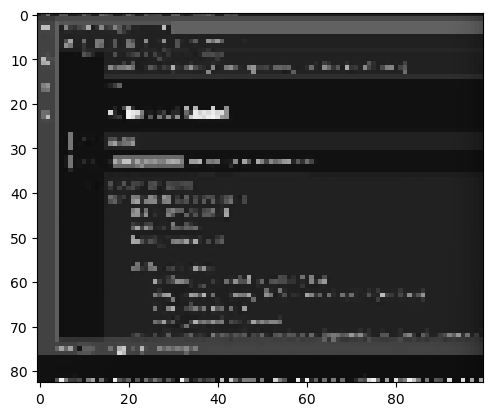

In [28]:
plt.imshow(cv2.cvtColor(env.get_observation()[0],cv2.COLOR_BGR2RGB))

In [5]:
done, done_cap=env.get_done()

In [6]:
env.reset()

array([[[33, 33, 33, ..., 17, 17, 17],
        [33, 33, 33, ..., 17, 17, 17],
        [33, 33, 33, ..., 17, 17, 17],
        ...,
        [50, 50, 50, ..., 17, 17, 17],
        [50, 50, 50, ..., 17, 17, 17],
        [50, 50, 50, ..., 17, 17, 17]]], shape=(1, 83, 100), dtype=uint8)

In [7]:
env.render()

In [8]:
env.action_space.sample()

2

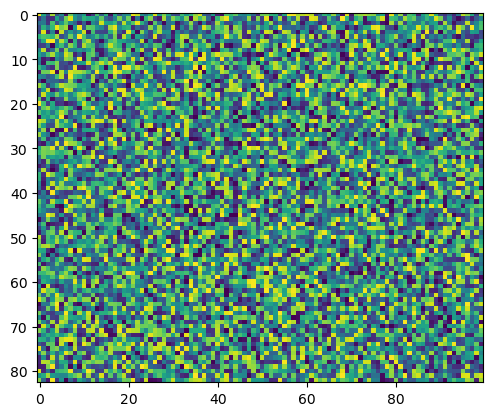

In [32]:
plt.imshow(env.observation_space.sample()[0])

In [9]:
env=WebGame()

In [10]:
obs=env.get_observation()

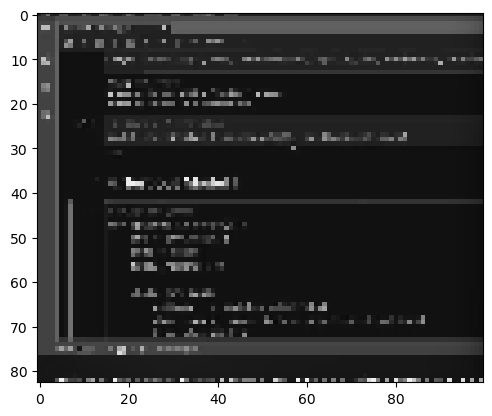

In [35]:
plt.imshow(cv2.cvtColor(obs[0],cv2.COLOR_BGR2RGB))

In [11]:
done, done_cap=env.get_done()
print(done)

False


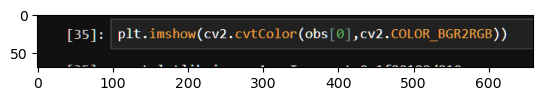

In [37]:
plt.imshow(done_cap)

In [38]:
for episode in range(10):
    obs, info = env.reset()
    done = False
    total_reward = 0

    while not done:
        obs, reward, terminated, truncated, info = env.step(
            env.action_space.sample()
        )
        done = terminated or truncated
        total_reward += reward

    print(f'Total reward for episode {episode} is {total_reward}')

KeyboardInterrupt: 

  DQN

In [12]:
#import as for file path management 
import os 

#import Base Callback for Saving Models
from stable_baselines3.common.callbacks import BaseCallback 
#check Environment 

from stable_baselines3.common import env_checker


In [13]:
#check that the environment is okay
env_checker.check_env(env)

AssertionError: Your environment must inherit from the gymnasium.Env class cf. https://gymnasium.farama.org/api/env/

In [14]:
import os
from stable_baselines3.common.callbacks import BaseCallback


class TrainAndLoggingCallback(BaseCallback):

    def __init__(self, check_freq, save_path, verbose=1):
        super(TrainAndLoggingCallback, self).__init__(verbose)
        self.check_freq = check_freq
        self.save_path = save_path

    def _init_callback(self):
        if self.save_path is not None:
            os.makedirs(self.save_path, exist_ok=True)

    def _on_step(self):
        if self.n_calls % self.check_freq == 0:
            model_path = os.path.join(
                self.save_path,
                f"best_model_{self.n_calls}"
            )
            self.model.save(model_path)

        return True
        

In [15]:
CHECKPOINT_DIR="./train/"
LOG_DIR="./LOGS/"

In [16]:
callback=TrainAndLoggingCallback(check_freq=1000,save_path=CHECKPOINT_DIR)

In [17]:
#import the DQN algarithm

from stable_baselines3 import DQN

In [19]:
#create the DQN model

model=DQN("CnnPolicy",env, tensorboard_log=LOG_DIR, verbose=1,
        buffer_size=10_0000,learning_starts=1000)

NameError: name 'DQN' is not defined

In [18]:
#kick off traning 

model.learn(total_timesteps=10000, callback=callback)

NameError: name 'model' is not defined

In [17]:
action,_=model.predict(obs)


NameError: name 'model' is not defined

In [ ]:
for episode in range(1):
    obs, info = env.reset()
    done = False
    total_reward = 0

    while not done:
        action, _ = model.predict(obs)
        obs, reward, terminated, truncated, info = env.step(int(action))

        done = terminated or truncated
        time.sleep(0.001)
        total_reward += reward

    print(f'Total reward for episode {episode} is {total_reward}')
    time.sleep(2)

In [20]:
!git init


Initialized empty Git repository in C:/Users/nowsh/Downloads/Dino project/.git/


In [21]:
!git add README.md


fatal: pathspec 'README.md' did not match any files


In [22]:
!git commit -m "first commit"


On branch master

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.ipynb_checkpoints/
	best_model/
	dino.ipynb

nothing added to commit but untracked files present (use "git add" to track)


In [23]:
!git branch -M main


In [24]:
!git remote add origin https://github.com/nowshadmahbub19-sudo/-Dino-Game-AI-Deep-Q-Network-DQN-.git


In [27]:
!git push -u origin main

error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/nowshadmahbub19-sudo/-Dino-Game-AI-Deep-Q-Network-DQN-.git'
